In [1]:

import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex":True,
    "font.family":"Helvetica",
    "font.size"  : 13,
})

# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import from_numpy
from sklearn.model_selection import train_test_split

from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.cuda.empty_cache()
# device = 'cpu'
# Set the plotting style
#plt.style.use('seaborn-poster')

from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn

from os import listdir
from os.path import isfile, join

from copy import deepcopy

#from getdist import MCSamples, plots

import pickle as pk

from hyperparameters import hparams

In [2]:
import sys
sys.path.append('./src')
from hyperparameters import hparams
from C3NN import C3NN
from load_data import load_data
from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn
import numpy as np
import random
from torch import from_numpy
import torch
import time, datetime
import cloudpickle as cpk

In [3]:
training_parameters, training_data = load_data(hparams)
training_parameters, training_data = training_parameters, training_data

In [64]:
class Regressor(nn.Module):
    def __init__(self, hidden_dim):
        super(Regressor, self).__init__()
        #self.c3nn = C3NN(hparams)#.to(device='cuda')

        self.conv1 = nn.Conv2d(4, 32, kernel_size=35, stride=1, padding=1)  # -> 32 feature maps
        self.conv2 = nn.Conv2d(32, 64, kernel_size=10, stride=1, padding=1)          # -> 64 feature maps
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)  # halve H and W each time
        
        
        #self.fc1 = nn.Linear(hparams.order*hparams.num_filts, hidden_dim)
        self.fc1 = nn.Linear(9600, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc3 = nn.Linear(hidden_dim, 8)
        
        self.parallel = torch.vmap(self.forward_single, in_dims=0, out_dims=0)

    def forward(self, x):
        #x = torch.mean(self.parallel(x), 1)
        x = self.parallel(x)
        x = x.view(x.size(0), -1)
        #x = self.c3nn(x)
        x = self.fc1(x)      # first linear layer
        x = self.relu(x)     # activation
        x = self.fc2(x)      # first linear layer
        x = self.relu(x)     # activation
        x = self.fc3(x)      # output layer
        return x

    def forward_single(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        #x = self.pool(F.relu(self.conv3(x)))
        return x

model = Regressor(64).to('cuda')

In [65]:
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from torch import nn, optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import copy
import math

def train_model(model, train_loader, val_loader, device,
                num_epochs=100,
                criterion=None,
                optimizer=None,
                lr=1e-3,
                # Early stopping:
                es_patience=10,
                es_min_delta=0.0,
                # LR scheduler on plateau:
                lr_factor=0.1,
                lr_patience=5,
                lr_min=1e-6,
                lr_threshold=1e-4):
    """
    Trains a regression model with MSE loss and reports MSE, RMSE, and MAE.
    Adds: Early stopping (on val MSE) and ReduceLROnPlateau scheduler.

    Returns:
        model (best weights restored), history (list of dicts per epoch)
    """
    model = model.to(device)
    if criterion is None:
        criterion = nn.MSELoss()
    if optimizer is None:
        optimizer = optim.Adam(model.parameters(), lr=lr)

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=lr_factor,
        patience=lr_patience,
        threshold=lr_threshold,
        threshold_mode='rel',
        min_lr=lr_min,
        verbose=False
    )

    print('Starting Training...')
    best_val = math.inf
    best_state = copy.deepcopy(model.state_dict())
    es_counter = 0
    history = []

    for epoch in range(num_epochs):
        # -------- TRAIN --------
        model.train()
        train_mse_sum, train_mae_sum, n_train = 0.0, 0.0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            pred = model(x)
            loss = criterion(pred, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            with torch.no_grad():
                bsz = y.size(0)
                n_train += bsz
                train_mse_sum += torch.mean((pred - y) ** 2).item() * bsz
                train_mae_sum += torch.mean(torch.abs(pred - y)).item() * bsz

        train_mse = train_mse_sum / n_train
        train_rmse = train_mse ** 0.5
        train_mae = train_mae_sum / n_train

        # -------- VALIDATION --------
        model.eval()
        val_mse_sum, val_mae_sum, n_val = 0.0, 0.0, 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                pred = model(x)
                val_mse_sum += torch.mean((pred - y) ** 2).item() * y.size(0)
                val_mae_sum += torch.mean(torch.abs(pred - y)).item() * y.size(0)
                n_val += y.size(0)

        val_mse = val_mse_sum / n_val
        val_rmse = val_mse ** 0.5
        val_mae = val_mae_sum / n_val

        # ---- Scheduler step on validation metric ----
        scheduler.step(val_mse)
        current_lr = optimizer.param_groups[0]['lr']

        # ---- Logging ----
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train: MSE {train_mse:.6f} | RMSE {train_rmse:.6f} | MAE {train_mae:.6f} || "
            f"Val: MSE {val_mse:.6f} | RMSE {val_rmse:.6f} | MAE {val_mae:.6f} || "
            f"LR: {current_lr:.2e}"
        )

        history.append({
            "epoch": epoch + 1,
            "train_mse": train_mse, "train_rmse": train_rmse, "train_mae": train_mae,
            "val_mse": val_mse, "val_rmse": val_rmse, "val_mae": val_mae,
            "lr": current_lr
        })

        # ---- Early stopping (on val_mse) ----
        if val_mse < (best_val - es_min_delta):
            best_val = val_mse
            best_state = copy.deepcopy(model.state_dict())
            es_counter = 0
        else:
            es_counter += 1
            if es_counter >= es_patience:
                print(f"Early stopping triggered at epoch {epoch+1}. Best val MSE: {best_val:.6f}")
                break

    # restore best weights
    model.load_state_dict(best_state)
    return model, history


In [67]:
# ----------------------------
# Convert tensors to Datasets & Loaders
# ----------------------------
training_parameters_mean = training_parameters.mean(0)
training_parameters_std = training_parameters.std(0)
training_parameters_stand = (training_parameters - training_parameters_mean) / training_parameters_std

X_train, X_val, y_train, y_val = train_test_split(training_data, training_parameters_stand, test_size=0.1, random_state=42)
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
device = 'cuda'
model, history = train_model(model, train_loader, val_loader, device, num_epochs=200, lr=1e-2, es_patience=20)

Starting Training...
Epoch [1/200] Train: MSE 0.957472 | RMSE 0.978505 | MAE 0.833839 || Val: MSE 0.912238 | RMSE 0.955112 | MAE 0.814367 || LR: 1.00e-02
Epoch [2/200] Train: MSE 0.920345 | RMSE 0.959346 | MAE 0.813890 || Val: MSE 0.954750 | RMSE 0.977113 | MAE 0.822222 || LR: 1.00e-02
Epoch [3/200] Train: MSE 0.877706 | RMSE 0.936859 | MAE 0.791155 || Val: MSE 0.923871 | RMSE 0.961182 | MAE 0.814990 || LR: 1.00e-02
Epoch [4/200] Train: MSE 0.829848 | RMSE 0.910960 | MAE 0.764215 || Val: MSE 0.972278 | RMSE 0.986042 | MAE 0.823976 || LR: 1.00e-02
Epoch [5/200] Train: MSE 0.758762 | RMSE 0.871070 | MAE 0.724299 || Val: MSE 1.047798 | RMSE 1.023620 | MAE 0.857121 || LR: 1.00e-02
Epoch [6/200] Train: MSE 0.700452 | RMSE 0.836930 | MAE 0.691219 || Val: MSE 1.151457 | RMSE 1.073060 | MAE 0.880320 || LR: 1.00e-02
Epoch [7/200] Train: MSE 0.623470 | RMSE 0.789601 | MAE 0.640879 || Val: MSE 1.117421 | RMSE 1.057081 | MAE 0.870419 || LR: 1.00e-03
Epoch [8/200] Train: MSE 0.530485 | RMSE 0.72834

In [68]:
%matplotlib inline
def plot_regression_predictions(y_true, y_pred, feature_names=None):
    """
    Plots prediction vs truth for each dimension of a multi-output regression.

    Args:
        y_true: torch.Tensor or np.ndarray of shape (N, D) with ground truth values
        y_pred: torch.Tensor or np.ndarray of shape (N, D) with predictions
        feature_names: list of strings for axis labels, length D (optional)
    """

    # Convert to numpy if torch tensors
    if hasattr(y_true, "detach"):
        y_true = y_true.detach().cpu().numpy()
    if hasattr(y_pred, "detach"):
        y_pred = y_pred.detach().cpu().numpy()

    D = y_true.shape[1]
    ncols = 4
    nrows = int(np.ceil(D / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = axes.flatten()

    for d in range(D):
        ax = axes[d]
        ax.scatter(y_true[:, d], y_pred[:, d], alpha=0.6)
        min_val = min(y_true[:, d].min(), y_pred[:, d].min())
        max_val = max(y_true[:, d].max(), y_pred[:, d].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'r--')  # y=x line
        label = feature_names[d] if feature_names else f"Dim {d+1}"
        ax.set_title(f"Prediction vs Truth: {label}")
        ax.set_xlabel("Truth")
        ax.set_ylabel("Prediction")

    # Remove unused subplots if any
    for d in range(D, len(axes)):
        fig.delaxes(axes[d])

    plt.tight_layout()
    plt.show()
    #plt.savefig('Plots/mse_testing.png')

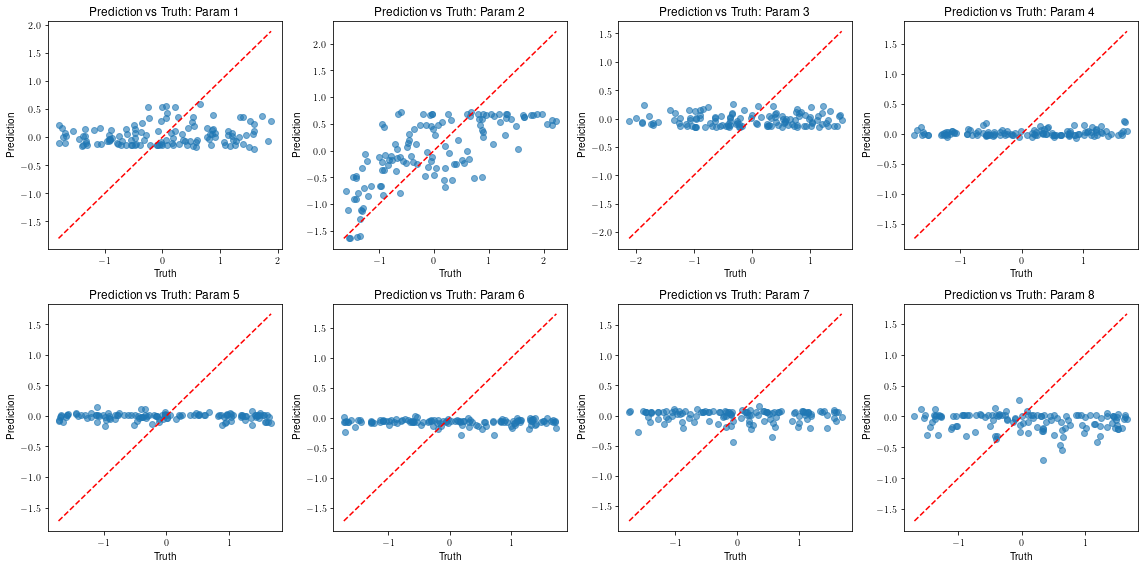

In [69]:
# Suppose y_true and y_pred are torch tensors of shape (N, 8)
model.eval()
y_pred = model(X_val)
plot_regression_predictions(y_val, y_pred,
                            feature_names=[f"Param {i+1}" for i in range(8)])

In [8]:
y_val

tensor([[ 1.2855e+00, -8.3969e-02,  1.5547e+00, -1.5952e-01,  1.5294e+00,
         -6.0850e-01, -1.1512e+00,  8.2676e-01],
        [-1.7773e-01, -5.7222e-02,  1.3653e+00,  7.3490e-02,  8.6592e-01,
          1.2348e+00, -1.3443e+00,  8.2973e-02],
        [-4.1480e-01,  6.7641e-01,  1.0696e+00,  7.2186e-01, -1.5050e+00,
          1.5646e-01, -2.6016e-01, -1.4386e+00],
        [-1.7113e+00,  2.2583e+00,  1.2267e+00, -1.3588e-01, -1.0807e+00,
         -7.5340e-01,  1.4948e+00,  1.9845e-01],
        [-7.5189e-01,  1.8800e+00,  9.5415e-01, -3.2836e-01, -1.5219e+00,
          1.5549e+00,  1.1187e+00,  7.7921e-01],
        [-1.4068e-01,  3.9366e-01, -5.1018e-01,  1.4040e+00, -1.2154e+00,
          1.0528e+00, -1.2969e+00, -7.5251e-01],
        [-8.3709e-01,  4.3951e-01,  8.3867e-01, -1.5272e+00,  8.1877e-01,
          2.0363e-01, -7.9545e-01,  1.0271e+00],
        [ 8.7058e-01, -5.1192e-01,  2.9820e-01, -1.2942e+00,  1.0444e+00,
          1.3865e+00, -7.7174e-01,  7.7242e-01],
        [-1.1753

In [9]:
print(y_val-y_pred)

tensor([[ 8.6998e-01, -1.7510e-01,  2.0010e+00, -1.2475e-01,  1.5806e+00,
         -5.2074e-01, -1.1585e+00,  7.9942e-01],
        [-2.6191e-01,  1.4817e-01,  1.3047e+00,  2.1163e-03,  9.8437e-01,
          1.1578e+00, -1.3307e+00,  1.1193e-01],
        [-4.9178e-01,  4.7156e-01,  1.1979e+00,  7.3672e-01, -1.4789e+00,
          1.7121e-01, -2.5306e-01, -1.4330e+00],
        [ 2.6896e-01,  7.0823e-01, -8.7568e-03, -2.1337e-02, -1.3229e+00,
         -7.9244e-01,  1.5236e+00,  3.6106e-01],
        [ 4.7432e-02,  6.2223e-01,  7.2218e-01, -1.5401e-01, -1.7490e+00,
          1.6450e+00,  1.1265e+00,  8.2030e-01],
        [ 1.7765e-01, -3.8338e-02, -6.7160e-01,  1.4264e+00, -1.2405e+00,
          1.0449e+00, -1.2828e+00, -7.2259e-01],
        [ 2.2485e-01, -4.7448e-01,  1.5392e-01, -1.4827e+00,  6.9023e-01,
          1.4962e-01, -7.6401e-01,  1.1092e+00],
        [ 1.3971e+00, -1.0192e+00, -4.6014e-02, -1.2877e+00,  1.0138e+00,
          1.3425e+00, -7.4756e-01,  8.2362e-01],
        [-2.3025

In [10]:
# in the next step I could use the extracted summaries to train sbi now...